# Long Report TDT4173







### Group info

Group: 10 \
Kaggle name: [10] Vintage ML in Theory \
Team Members: Henrik Remmen (541747), Elias Melkeraaen (563433) and Christian Økland (560367) 


## Introduction

The goal of this project is to forecast incoming raw material deliveries for Hydro’s operations.  
We approached this by developing machine learning models using the Darts framework, specifically implementations of LightGBM and XGBoost adapted for time series forecasting.  


## Evaluation Criteria and Deductions

This section summarizes potential point deductions and shows where each requirement has been addressed in the report.

Pass individual assignment at second chance: (N/A)

Late submission of project: (N/A)

No Exploratory Data Analysis
Covered through:  
- [2.1 Domain knowledge], [2.2 Observations], [2.3 Data generation],  
- [2.4.1 Exploring individual features] [2.4.2 Exploring paired features], and [2.4.3 Feature Selection].

Only One Type of Predictor Used
Addressed in:  
- [ 3.2 LightGBM Model Setup] and [3.2 XGBoost Model Setup], showing that multiple model types were tested.

No Feature Engineering
Addressed in:  
- [2.4.3 Feature Selection], [2.4.1 Exploring individual features],  
and [3.2 Model setup], where various derived and transformed features were applied.

No Model Interpretation
Addressed in:  
- [5.1 Global Feature Importance], [5.2 Partial Dependence Analysis],  
- [5.3 Local Explanation Techniques], and [5.4 Interpretation Summary and Discussion],  
demonstrating both global and local model interpretation efforts.

## 1.2) Imports, Data paths and Global variables

In the project we used the following libraries and the receivals, purchase_orders and materials data from the project. The selection of rm_ids will be decribed more in section 2.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from typing import List
import seaborn as sns
import warnings
import os
import shap


from darts import TimeSeries
from darts.models import LightGBMModel
from darts.models import XGBModel

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="pandas")
warnings.filterwarnings("ignore", message="X does not have valid feature names", category=UserWarning)
os.environ["LIGHTGBM_VERBOSE"] = "0"
os.environ["LIGHTGBM_VERBOSITY"] = "0"

RECEIVALS_PATH = Path("./data/kernel/receivals.csv")
PURCHASE_ORDERS_PATH = Path("./data/kernel/purchase_orders.csv")
MATERIALS_PATH = Path("./data/extended/materials.csv")
FORECAST_START = pd.Timestamp("2025-01-01")
FORECAST_END   = pd.Timestamp("2025-05-31")
TRAIN_END      = pd.Timestamp("2024-12-19")
FEATURE_END    = TRAIN_END

INCLUDE_RM_IDS = {
    2130, 2131, 2132, 2134, 2135, 2142, 2143, 2144, 
    2145, 2741, 3122, 3123, 3124, 3125, 3126, 
    3282, 3362, 3421, 3781, 3865, 3901, 4222
}

## 1.2) Utility functions


In [28]:
# Helper function to concvert columns to datetime
def _to_datetime_col(df: pd.DataFrame, col: str, dayfirst: bool | None = None) -> pd.Series:
    if col not in df.columns:
        raise KeyError(f"Kolonnen '{col}' finnes ikke i DataFrame.")
    s = df[col]
    if np.issubdtype(s.dtype, np.number):
        dt = pd.to_datetime(s, unit="ms", errors="coerce")
        if dt.isna().all():
            dt = pd.to_datetime(s, unit="s", errors="coerce")
    else:
        dt = pd.to_datetime(s, errors="coerce", dayfirst=dayfirst, infer_datetime_format=True, utc=True)
    if hasattr(dt, "dt"):
        dt = dt.dt.tz_localize(None).dt.normalize()
    return dt

# Load receivals data
def load_receivals() -> pd.DataFrame:
    df = pd.read_csv(RECEIVALS_PATH).copy()
    df.columns = df.columns.str.strip()
    if "date_arrival" in df.columns:
        df["actual_delivery_date"] = _to_datetime_col(df, "date_arrival")
    else:
        df["actual_delivery_date"] = _to_datetime_col(df, "actual_delivery_date")
    keep = ["rm_id", "net_weight", "actual_delivery_date", "purchase_order_id", "purchase_order_item_no"]
    df = df[[c for c in keep if c in df.columns]].copy()
    for c in ["rm_id","net_weight","purchase_order_id","purchase_order_item_no"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.rename(columns={"actual_delivery_date": "date_arrival"})
    df["date_arrival"] = _to_datetime_col(df, "date_arrival")
    if "net_weight" not in df.columns:
        df["net_weight"] = 0.0
    return df

# Load purchase orders data
def load_purchase_orders() -> pd.DataFrame:
    if not PURCHASE_ORDERS_PATH.exists():
        return pd.DataFrame(columns=["purchase_order_id","purchase_order_item_no","delivery_date"])
    po = pd.read_csv(PURCHASE_ORDERS_PATH).copy()
    po.columns = po.columns.str.strip()
    keep = ["purchase_order_id","purchase_order_item_no","delivery_date"]
    po = po[[c for c in keep if c in po.columns]].copy()
    if "delivery_date" in po.columns:
        po["delivery_date"] = _to_datetime_col(po, "delivery_date")
    for c in ["purchase_order_id","purchase_order_item_no"]:
        if c in po.columns:
            po[c] = pd.to_numeric(po[c], errors="coerce")
    return po

# Load materials data
def load_materials_latest() -> pd.DataFrame:
    candidate_paths = [Path("/mnt/data/materials.csv"), MATERIALS_PATH]
    mat_path = next((p for p in candidate_paths if Path(p).exists()), None)
    if mat_path is None:
        return pd.DataFrame(columns=["rm_id","raw_material_alloy","raw_material_format_type","stock_location"])

    df = pd.read_csv(mat_path).copy()
    df.columns = df.columns.str.strip()

    if "rm_id" not in df.columns:
        return pd.DataFrame(columns=["rm_id","raw_material_alloy","raw_material_format_type","stock_location"])

    df["rm_id"] = pd.to_numeric(df["rm_id"], errors="coerce")
    df = df[df["rm_id"].notna()].copy()
    df["rm_id"] = df["rm_id"].astype(int)

    for col in ["raw_material_alloy", "raw_material_format_type", "stock_location"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().replace("", "UNKNOWN").fillna("UNKNOWN")
        else:
            df[col] = "UNKNOWN"

    if "product_version" in df.columns:
        df["product_version"] = pd.to_numeric(df["product_version"], errors="coerce").fillna(-1)
        df_latest = (
            df.sort_values(["rm_id", "product_version"], kind="mergesort")
              .drop_duplicates(subset=["rm_id"], keep="last")
        )
    else:
        df_latest = df.drop_duplicates(subset=["rm_id"], keep="last")

    return df_latest[["rm_id","raw_material_alloy","raw_material_format_type","stock_location"]]

# Encode three material columns compactly
def encode_three_material_columns_compact(materials_df: pd.DataFrame) -> pd.DataFrame:
    if materials_df.empty:
        return pd.DataFrame(columns=["rm_id","alloy_code","format_type_code","location_code"])
    df = materials_df.copy()
    for col in ["raw_material_alloy","raw_material_format_type","stock_location"]:
        if col not in df.columns:
            df[col] = "UNKNOWN"
        df[col] = df[col].astype(str).str.strip().replace("", "UNKNOWN").fillna("UNKNOWN")

    def compact_factorize(s: pd.Series) -> pd.Series:
        unique_vals = [v for v in s.unique() if v != "UNKNOWN"]
        mapping = {v: i + 1 for i, v in enumerate(sorted(unique_vals))}
        mapping["UNKNOWN"] = 0
        return s.map(mapping).fillna(0).astype(int)

    df["alloy_code"]        = compact_factorize(df["raw_material_alloy"])
    df["format_type_code"]  = compact_factorize(df["raw_material_format_type"])
    df["location_code"]     = compact_factorize(df["stock_location"])
    return df[["rm_id","alloy_code","format_type_code","location_code"]]

# Build daily material signals
def build_daily_material_signals_fast(receivals_df: pd.DataFrame, materials_enc_df: pd.DataFrame) -> pd.DataFrame:
    if receivals_df.empty or materials_enc_df.empty:
        return pd.DataFrame(columns=["rm_id","date","alloy_code","format_type_code","location_code"])
    rec = receivals_df.copy()
    rec["date"] = pd.to_datetime(rec["date_arrival"]).dt.normalize()
    base = rec[["rm_id","date"]].drop_duplicates()
    return base.merge(materials_enc_df, on="rm_id", how="left")

# Add days since last delivery
def add_days_since_last(df_daily: pd.DataFrame, *, count_today_as_zero: bool = True) -> pd.DataFrame:
    d = df_daily.sort_values(["rm_id", "date"]).copy()
    out = []
    for _, g in d.groupby("rm_id", as_index=False):
        dates = pd.to_datetime(g["date"]).dt.normalize()
        has_deliv = g["y"].to_numpy() > 0
        last_deliv = dates.where(has_deliv).ffill()
        if not count_today_as_zero:
            last_deliv = last_deliv.shift(1)
        ds = (dates - last_deliv).dt.days.astype("float")
        ds = ds.fillna(method="bfill").fillna(len(g))
        out.append(ds)
    d["days_since_last"] = pd.concat(out).sort_index()
    return d

# Compact reindex used values in specified columns
def _compact_reindex_used_values(df: pd.DataFrame, cols: List[str]) -> pd.DataFrame:
    df = df.copy()
    for c in cols:
        used = sorted(v for v in df[c].unique() if v != 0)
        mapping = {v: i + 1 for i, v in enumerate(used)}
        df[c] = df[c].map(mapping).fillna(0).astype(int)
    return df

# Compute lateness per receival
def compute_lateness_per_receival(receivals_df: pd.DataFrame, po_df: pd.DataFrame) -> pd.DataFrame:
    recv, po = receivals_df.copy(), po_df.copy()
    recv.columns = recv.columns.str.strip()
    po.columns   = po.columns.str.strip()

    need_recv = {"purchase_order_id", "purchase_order_item_no", "rm_id", "date_arrival"}
    need_po   = {"purchase_order_id", "purchase_order_item_no", "delivery_date"}
    missing_r = need_recv - set(recv.columns)
    missing_p = need_po   - set(po.columns)
    if missing_r:
        raise KeyError(f"Receivals mangler kolonnene: {', '.join(sorted(missing_r))}")
    if missing_p:
        raise KeyError(f"PO-data mangler kolonnene: {', '.join(sorted(missing_p))}")

    recv["date_arrival"] = pd.to_datetime(recv["date_arrival"], errors="coerce").dt.normalize()
    po["delivery_date"]  = pd.to_datetime(po["delivery_date"],  errors="coerce").dt.normalize()
    recv["net_weight"]   = pd.to_numeric(recv.get("net_weight", 0.0), errors="coerce").fillna(0.0)

    agg_recv = (
        recv.groupby(
            ["purchase_order_id", "purchase_order_item_no", "rm_id", "date_arrival"],
            as_index=False
        ).agg(net_weight_sum=("net_weight", "sum"))
    )

    po_unique = (
        po[["purchase_order_id", "purchase_order_item_no", "delivery_date"]]
        .drop_duplicates(subset=["purchase_order_id", "purchase_order_item_no"])
    )

    merged = agg_recv.merge(
        po_unique,
        on=["purchase_order_id", "purchase_order_item_no"],
        how="left",
        suffixes=("", "_po")
    )

    merged["lateness_days"] = (merged["date_arrival"] - merged["delivery_date"]).dt.days

    out = (
        merged[["rm_id", "date_arrival", "delivery_date", "lateness_days", "net_weight_sum"]]
        .sort_values(["rm_id", "date_arrival"])
        .reset_index(drop=True)
    )
    return out
# Build RM lateness features
def build_rm_lateness_features(lateness_events: pd.DataFrame) -> pd.DataFrame:
    if lateness_events.empty:
        return pd.DataFrame(columns=["rm_id", "date", "rm_lateness_days", "rm_late_flag"])
    ev = lateness_events.copy()
    ev["date"] = pd.to_datetime(ev["date_arrival"]).dt.normalize()
    ev["lateness_days"] = pd.to_numeric(ev["lateness_days"], errors="coerce").fillna(0.0)
    daily = (
        ev.groupby(["rm_id", "date"], as_index=False)
          .agg(
              rm_lateness_days=("lateness_days", "mean"),
              rm_late_flag=("lateness_days", lambda x: int((x != 0).any()))
          )
          .sort_values(["rm_id", "date"])
          .reset_index(drop=True)
    )
    daily["rm_lateness_days"] = daily["rm_lateness_days"].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    daily["rm_late_flag"] = daily["rm_late_flag"].astype(int)
    return daily[["rm_id", "date", "rm_lateness_days", "rm_late_flag"]]

## 2) Explanatory Data Analysis ##

### 2.1) Domain knowledge:

In real logistics you do not get deliveries every day for every material. Some raw materials arrive in big batches, others come in small frequent shipments.
Delays, partial deliveries and seasonal patterns are normal. 

Since Hydro wants conservative forecasts (from task description), it makes sense because overestimating means planning melting that cannot happen.

This gives us intuition:
If the purchase order for a material is very big, there will come deliveries over time.






In [29]:
receivals = pd.read_csv("data/kernel/receivals.csv", parse_dates=["date_arrival"])
receivals.head()

,rm_id,product_id,purchase_order_id,purchase_order_item_no,receival_item_no,batch_id,date_arrival,receival_status,net_weight,supplier_id
0,365.0,91900143.0,208545.0,10.0,1,NaN,2004-06-15 13:34:00+02:00,Completed,11420.0,52062
1,365.0,91900143.0,208545.0,10.0,2,NaN,2004-06-15 13:34:00+02:00,Completed,13760.0,52062
2,365.0,91900143.0,208490.0,10.0,1,NaN,2004-06-15 13:38:00+02:00,Completed,11281.0,50468
3,365.0,91900143.0,208490.0,10.0,2,NaN,2004-06-15 13:38:00+02:00,Completed,13083.0,50468
4,379.0,91900296.0,210435.0,20.0,1,NaN,2004-06-15 13:40:00+02:00,Completed,23910.0,52577



Topp 30 rm_id med leveranser i 2024 (sortert etter total vekt):
  rm_id  2130: 15,030,729 kg
  rm_id  3865: 12,215,851 kg
  rm_id  3781: 10,633,107 kg
  rm_id  3125: 6,317,380 kg
  rm_id  3126: 6,226,620 kg
  rm_id  3124: 4,942,040 kg
  rm_id  3282: 4,877,980 kg
  rm_id  3122: 4,847,160 kg
  rm_id  3123: 4,043,100 kg
  rm_id  3901: 2,339,910 kg
  rm_id  2140: 2,115,140 kg
  rm_id  2134: 1,598,810 kg
  rm_id  2142: 1,216,846 kg
  rm_id  2135: 902,220 kg
  rm_id  3265: 652,080 kg
  rm_id  2131: 624,850 kg
  rm_id  4222: 589,920 kg
  rm_id  3362: 571,022 kg
  rm_id  2144: 556,094 kg
  rm_id  4443: 494,980 kg
  rm_id  2741: 494,460 kg
  rm_id  2145: 485,575 kg
  rm_id  3421: 393,306 kg
  rm_id  3883: 363,320 kg
  rm_id  2143: 350,531 kg
  rm_id  3761: 333,364 kg
  rm_id  2132: 300,469 kg
  rm_id  4263: 298,560 kg
  rm_id  3142: 284,360 kg
  rm_id  3642: 229,300 kg


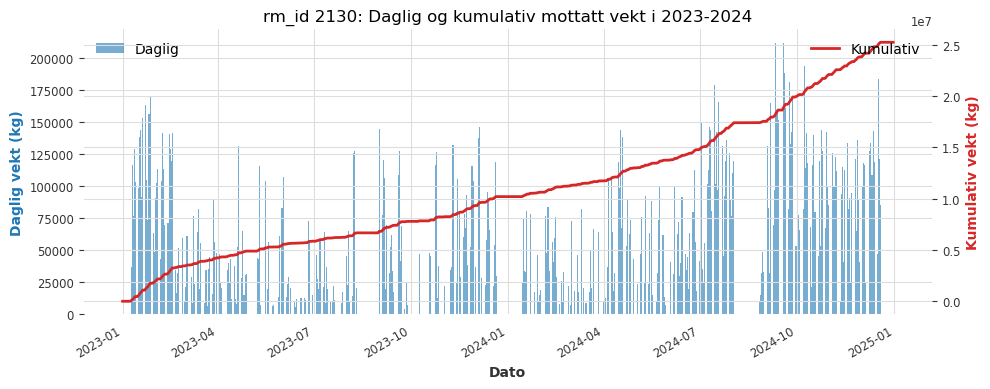

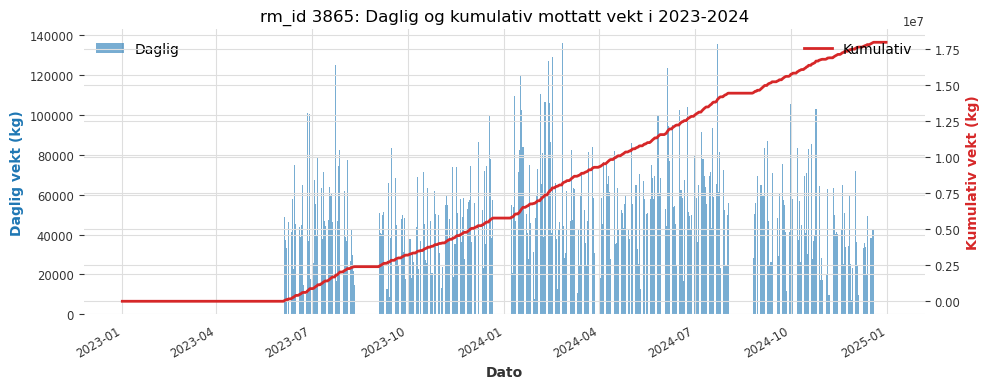

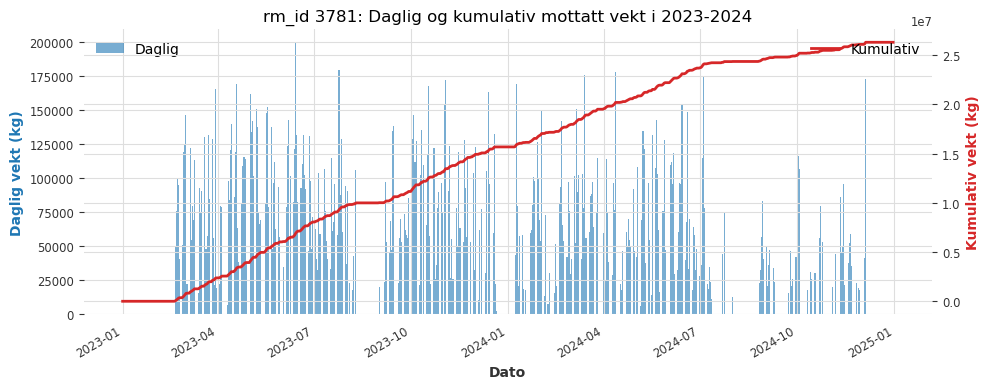

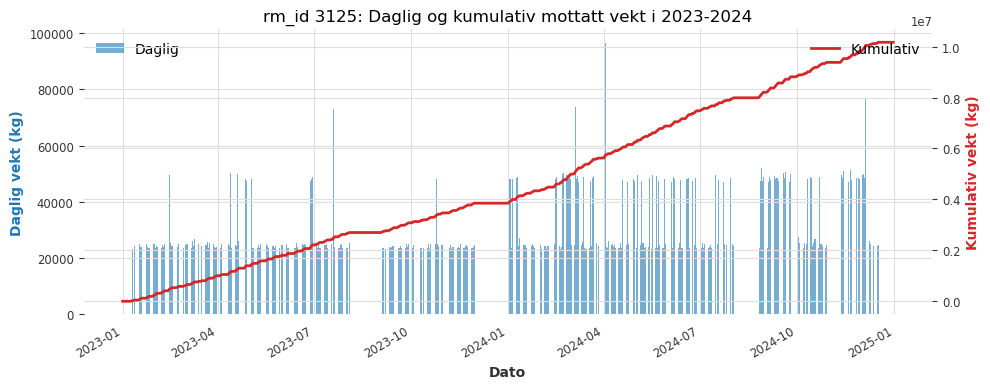

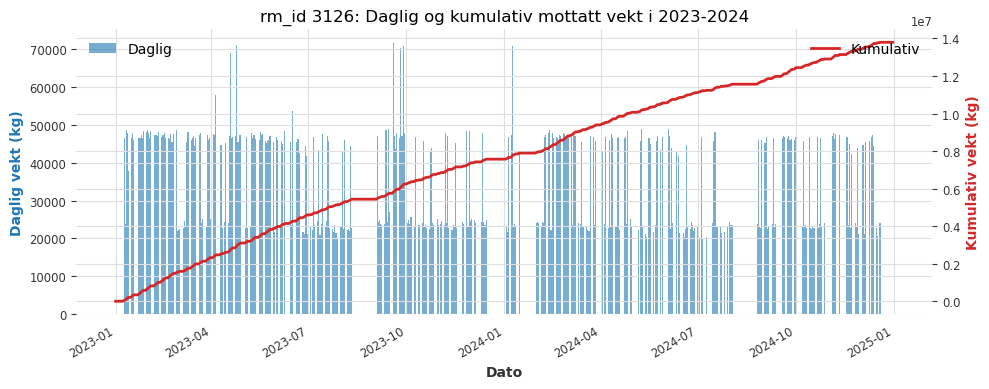

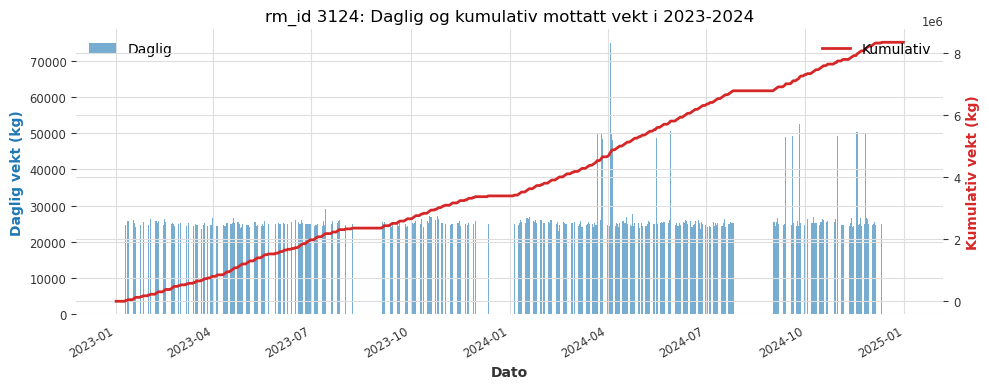

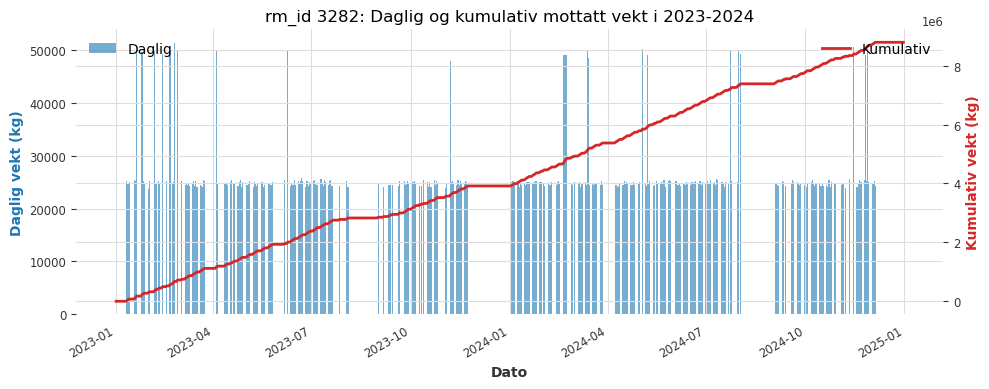

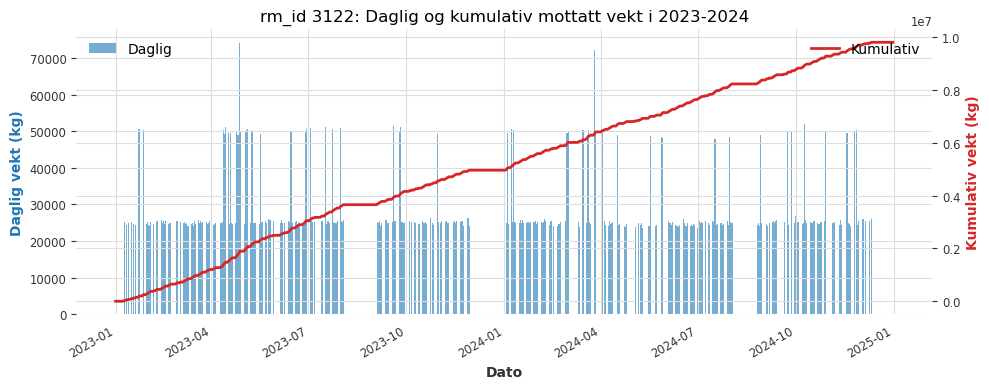

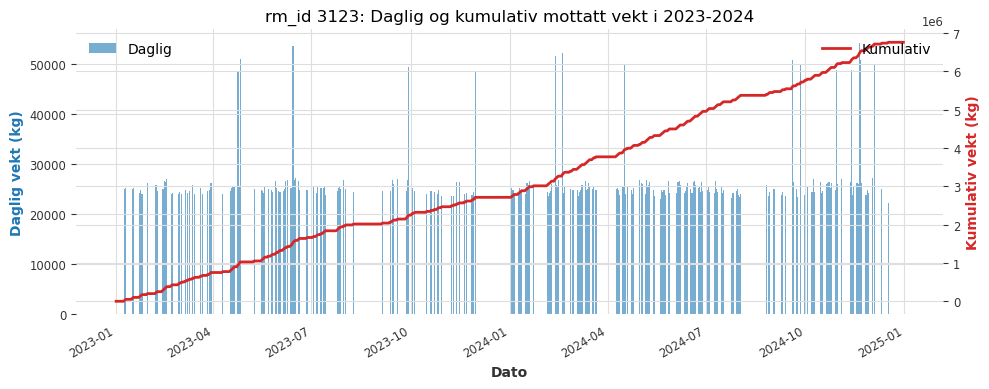

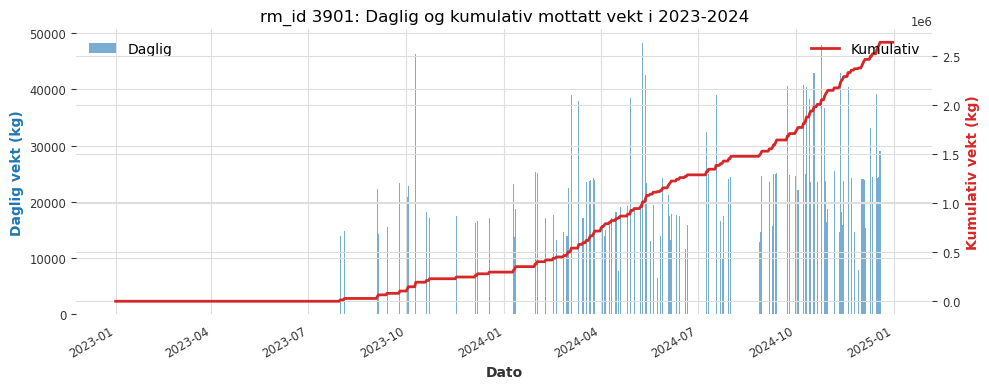

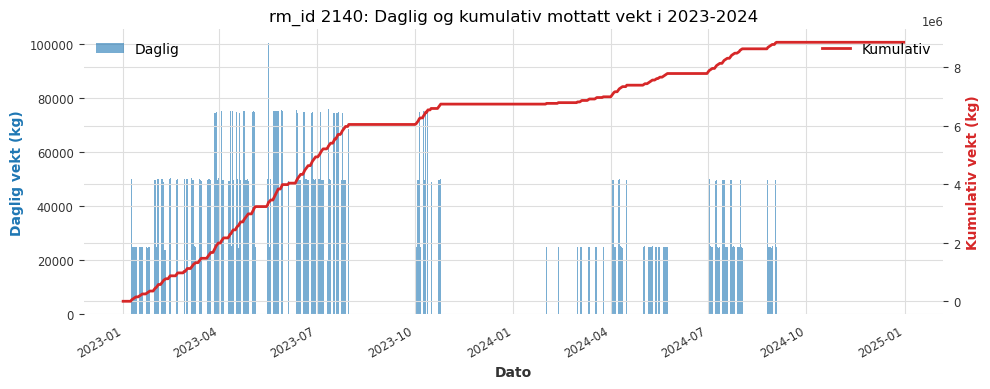

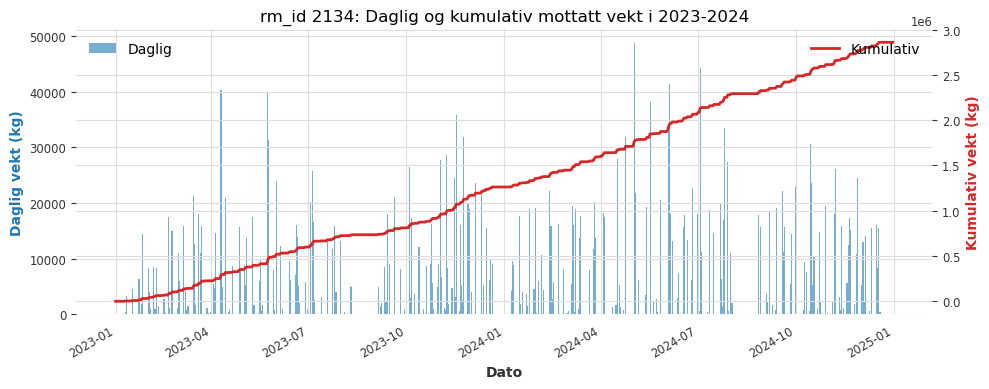

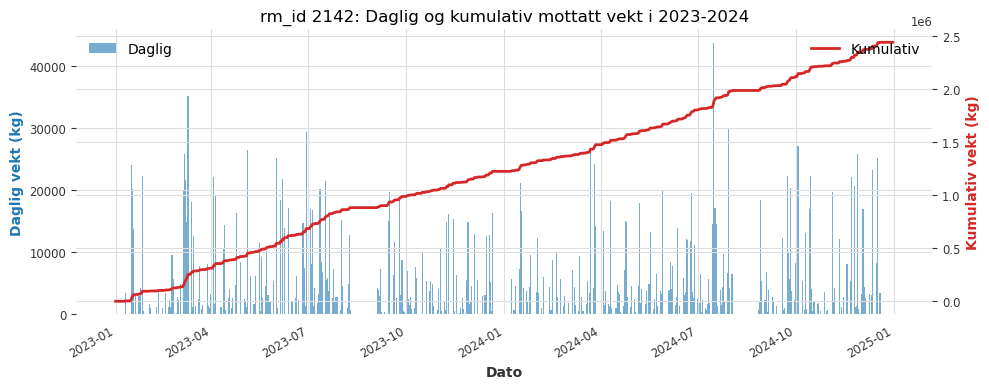

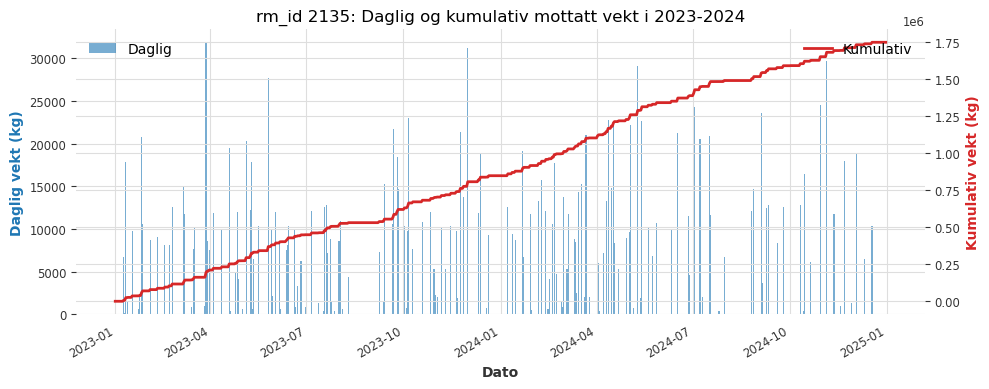

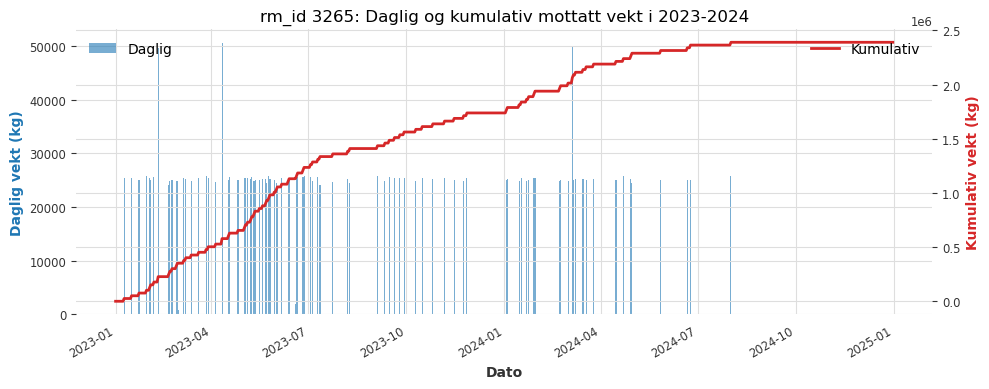

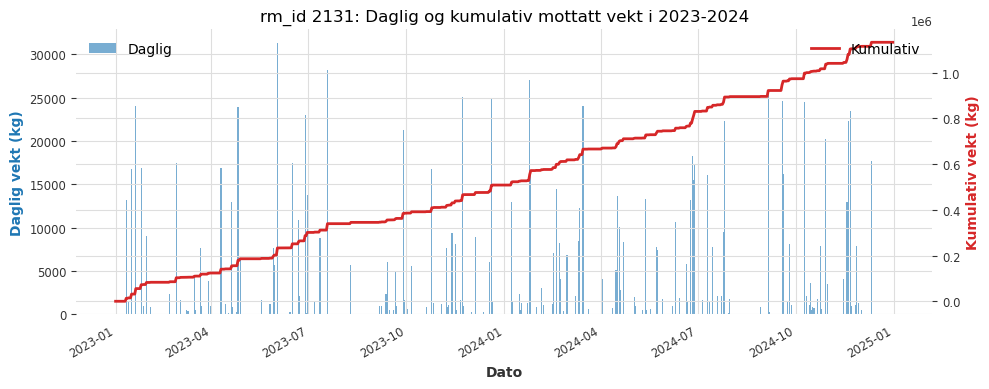

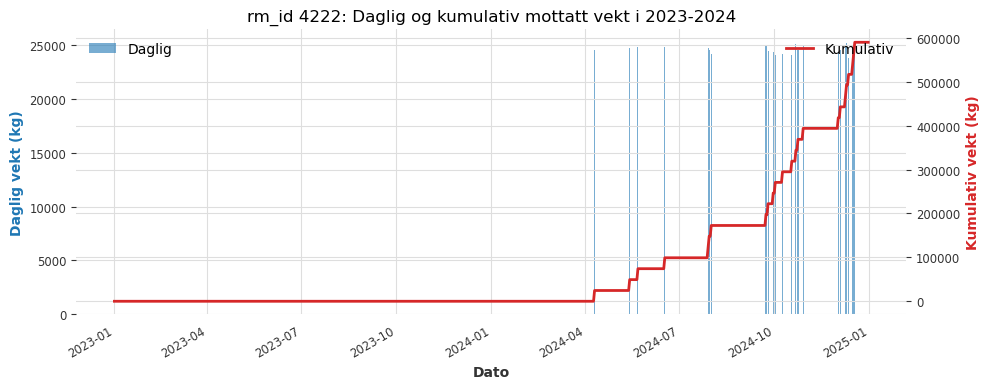

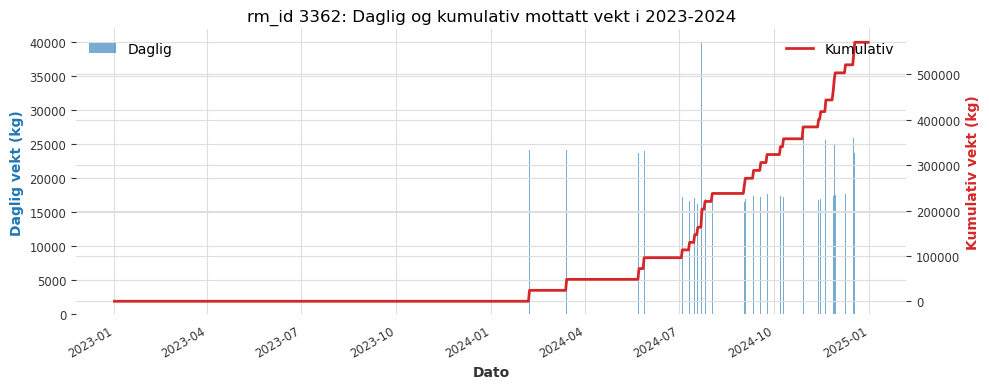

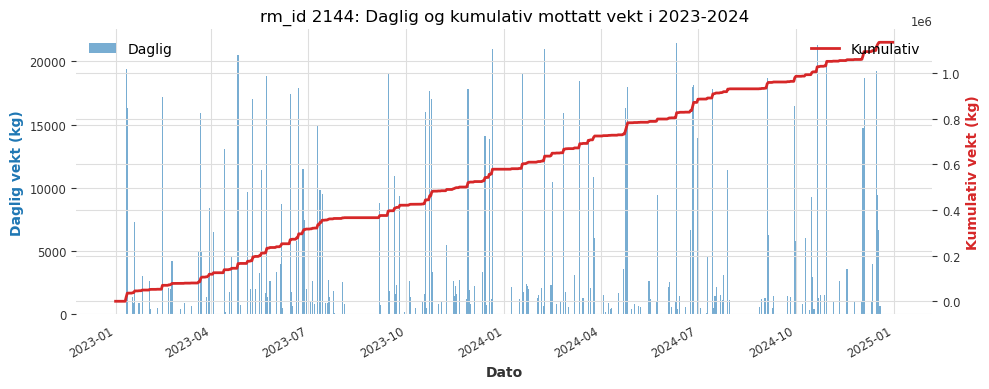

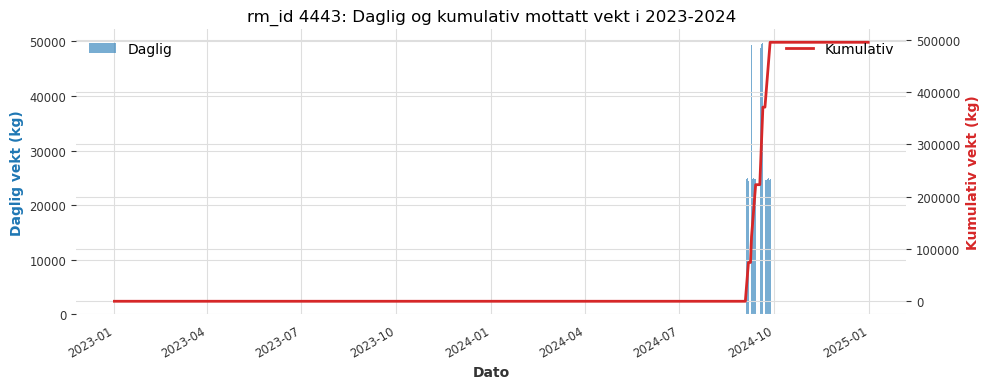

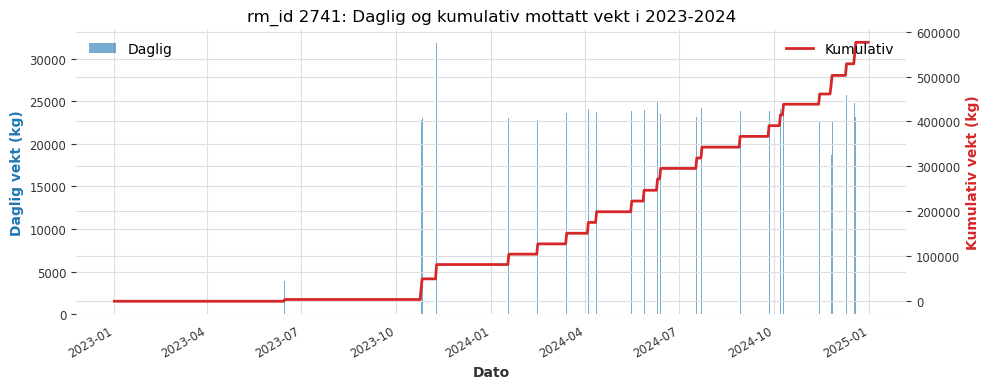

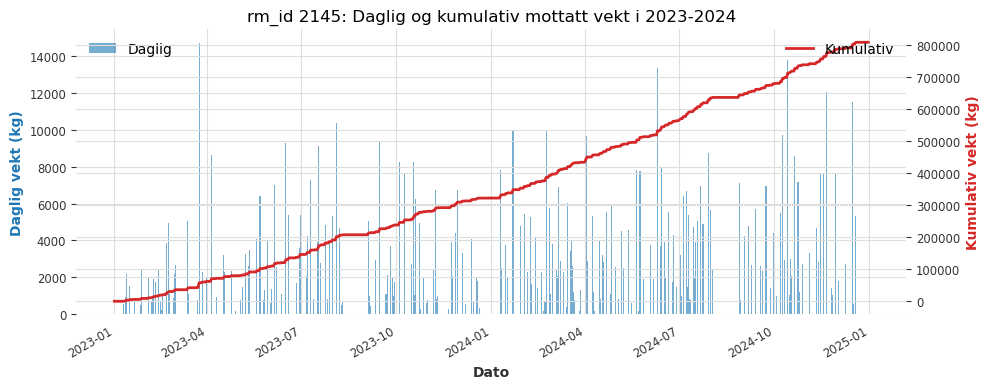

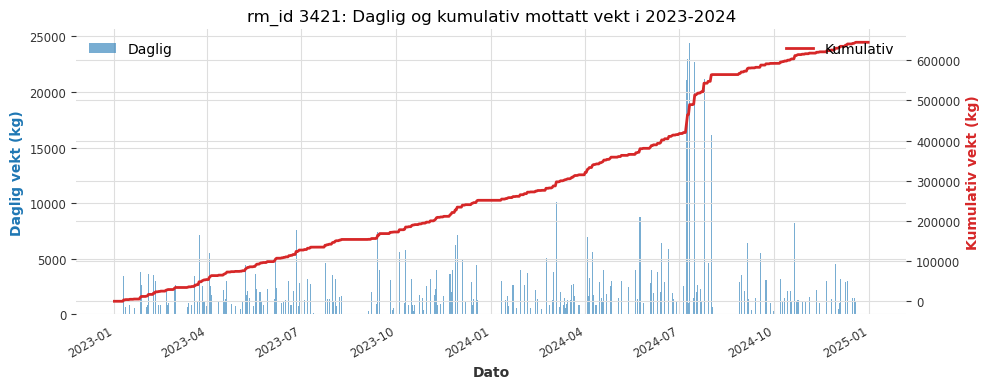

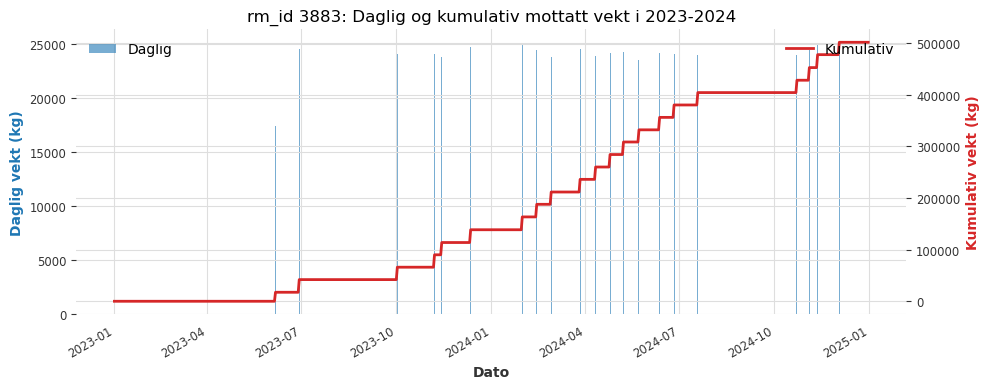

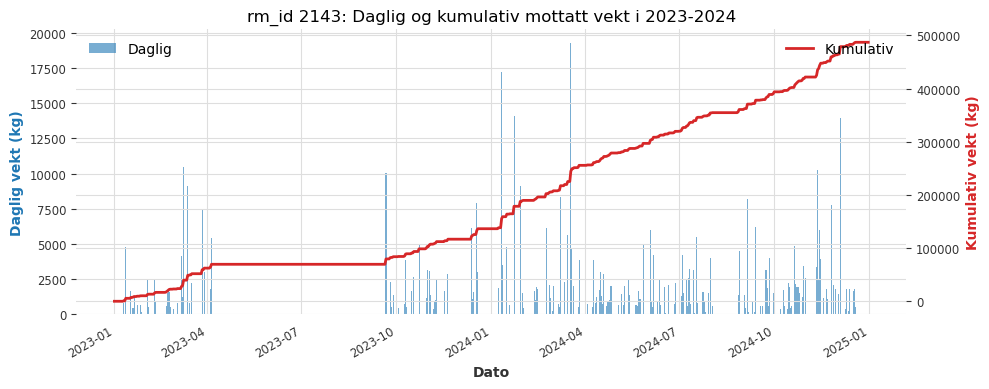

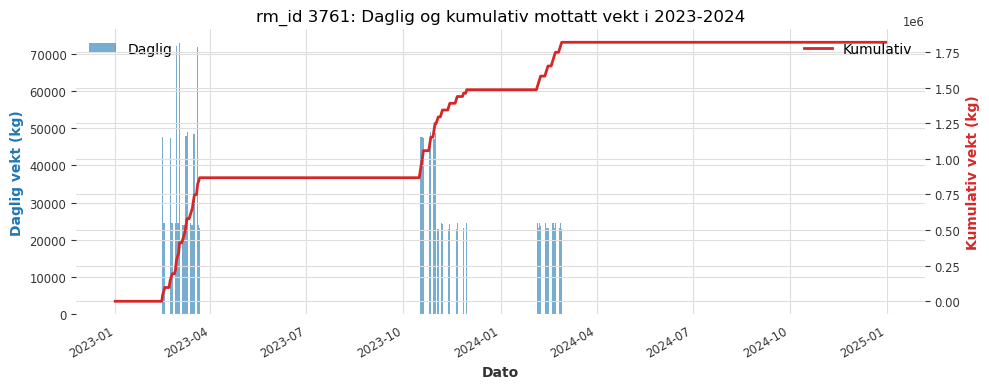

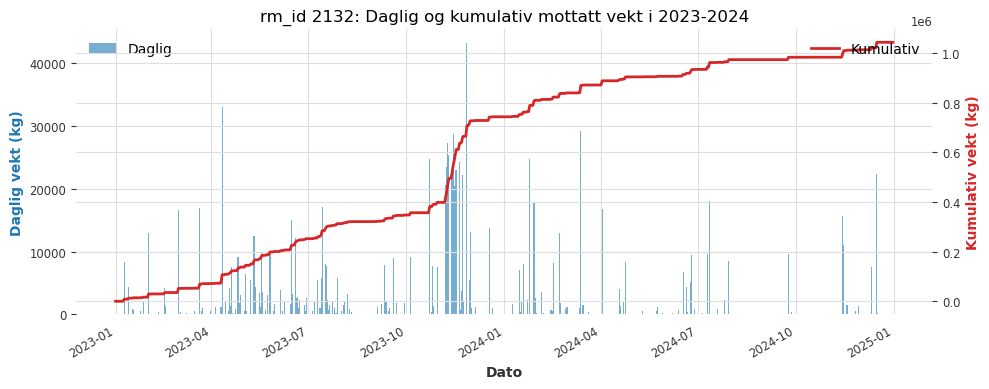

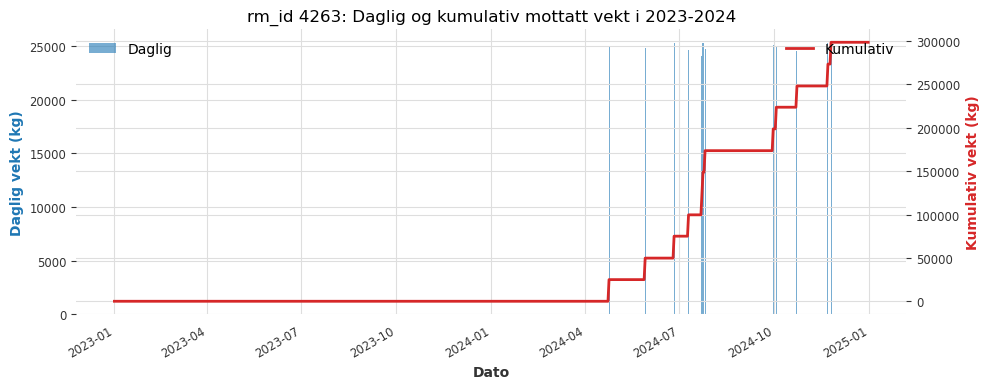

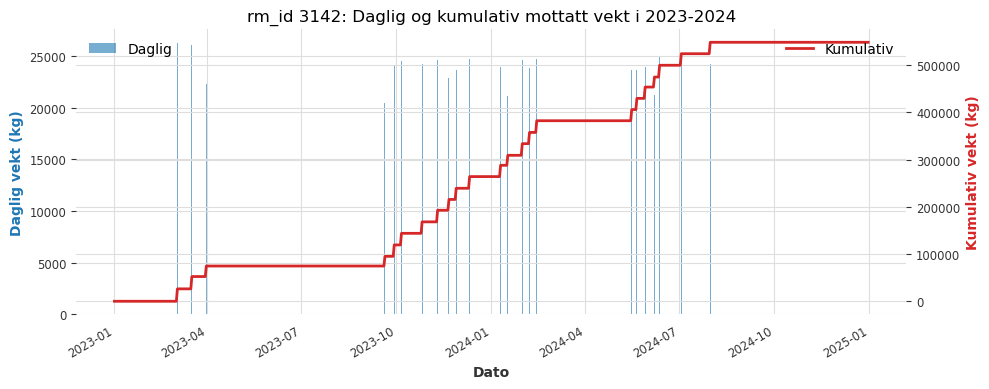

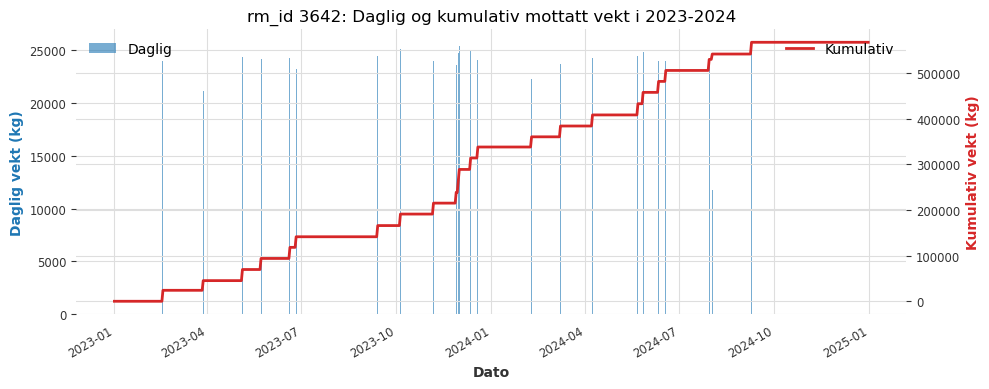

In [30]:
df = load_receivals().copy()

# --- Sikre riktige typer ---
df["date"] = pd.to_datetime(df["date_arrival"], errors="coerce").dt.normalize()
df["net_weight"] = pd.to_numeric(df.get("net_weight", 0.0), errors="coerce").fillna(0.0)
df["rm_id"] = pd.to_numeric(df["rm_id"], errors="coerce")

# --- Fjern ugyldige rader ---
df = df[df["date"].notna() & df["rm_id"].notna()]
df["year"] = df["date"].dt.year

# --- Filtrer til kun 2023 og 2024 ---
df = df[df["year"].isin([2023, 2024])].copy()

# --- Filtrer til rm_id som har data i 2024 ---
df_2024 = df[df["year"] == 2024].copy()
if df_2024.empty:
    raise RuntimeError("Ingen data for 2024 i mottaksfilen.")

# --- Finn topp 30 rm_id etter totalvekt i 2024 ---
top_rm = (
    df_2024.groupby("rm_id", dropna=False)["net_weight"]
    .sum()
    .sort_values(ascending=False)
    .head(30)
)
top_rm_ids = top_rm.index.astype(int).tolist()

# --- Print rm_idene og summer ---
print(f"\nTopp {len(top_rm_ids)} rm_id med leveranser i 2024 (sortert etter total vekt):")
for rm, total in top_rm.items():
    print(f"  rm_id {int(rm):>5}: {total:,.0f} kg")

# --- Plot ---
for rm in top_rm_ids:
    g = df[df["rm_id"].astype(int) == rm].copy()
    if g.empty:
        continue

    # Daglig summering og fyll ut dager uten leveranser
    daily = (
        g.groupby("date", as_index=False)["net_weight"]
         .sum()
         .sort_values("date")
    )
    full_idx = pd.date_range("2023-01-01", "2024-12-31", freq="D")
    daily = (
        daily.set_index("date")
             .reindex(full_idx, fill_value=0.0)
             .rename_axis("date")
             .reset_index()
    )
    daily["cum"] = daily["net_weight"].cumsum()

    # --- Plot ---
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax2 = ax1.twinx()

    ax1.bar(daily["date"], daily["net_weight"], width=1.0, align="center",
            color="tab:blue", alpha=0.6, label="Daglig")
    ax2.plot(daily["date"], daily["cum"], color="tab:red",
             linewidth=2.0, label="Kumulativ")

    ax1.set_title(f"rm_id {rm}: Daglig og kumulativ mottatt vekt i 2023-2024")
    ax1.set_xlabel("Dato")
    ax1.set_ylabel("Daglig vekt (kg)", color="tab:blue")
    ax2.set_ylabel("Kumulativ vekt (kg)", color="tab:red")

    ax1.legend(loc="upper left")
    ax2.legend(loc="upper right")

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()


### 2.2) Observations

During the initial data exploration, several observations were made about the dataset:

- The column `net_weight` contains only positive values, as expected for delivery quantities.  
- Timestamps increase consistently over time, showing no temporal errors.  
- Some columns contain missing values, but the key variables (`rm_id`, `date_arrival`, `net_weight`) are complete.  
- There are no negative weights or broken timestamps, which indicates that the data is clean and reliable.  

Overall, the dataset appears normal and realistic.

We also observed that a few `rm_id`s dominate the total delivery volume, while several others have very limited historical data.  
There is continuous delivery activity through the years, but the total volume varies strongly between periods.  
This pattern confirms that deliveries are time-dependent and not random, which supports the use of time series modeling.  
In addition, some `rm_id`s became active only partway through the dataset, while others started showing activity toward the end of the time period.  
Because of these differences, the available history varies considerably across `rm_id`s.  

To ensure that the model could learn meaningful patterns and avoid instability from sparse or inactive data, we focused the training on the most important and consistently active `rm_id`s.  
In addition to selecting materials that account for the majority of total deliveries, we prioritized those showing a strong upward trend toward the end of 2024, indicating ongoing or increasing activity.  
Conversely, `rm_id`s with a clear downward trend or no deliveries near the end of 2024 were excluded, as these materials were likely inactive or discontinued.  
This selection ensured that the model was trained on materials with stable and relevant recent activity, improving both accuracy and robustness of the forecasts.



In [31]:
purchase_orders = pd.read_csv("data/kernel/purchase_orders.csv", parse_dates=["delivery_date"])

merged = receivals.merge(
    purchase_orders,
    on=["purchase_order_id", "purchase_order_item_no"],
    how="left"
)

merged[["quantity", "net_weight"]].corr()


,quantity,net_weight
quantity,1.000000,0.077136
net_weight,0.077136,1.000000


The correlation is weak, meaning ordered and delivered amounts are not tightly linked on an individual record level.  
This makes sense: a single order may be split into several smaller deliveries, or some deliveries might belong to old orders.  
It suggests that order data provides limited short-term predictive power without aggregation or matching over time.

Summary of Findings
- Data covers multiple raw materials (rm_id), each with varying delivery frequency and volume.
- Deliveries show temporal patterns, suggesting the need for time-series or lag features.
- Missing data is minimal in key columns like `net_weight` and `date_arrival`.
- Strong relationship between ordered and received quantities.
- Variability across materials indicates the model should handle heterogeneity carefully.

### 2.3) Data Generation

According to the dataset description, each row in `receivals.csv` represents a single delivery event of a material,  
including a timestamp and the delivered weight. In other words, it is a chronological log of material deliveries.

We use this historical delivery information to model and predict the total volume of incoming materials for 2025 by aggregating and analyzing deliveries over time.

The receivals data is supplemented with other datasets that provide additional context:  
- Purchase orders – containing information such as quantity and expected delivery date.  
- Materials – describing attributes like material type, format, and storage location.  
- Transportation – providing supporting information about how materials are delivered.  

Together, these datasets offer a structured view of the material flow and timing of deliveries throughout the observation period.


### 2.4) Feature Engineering

In [32]:
RECEIVALS_MIN_DATE   = pd.Timestamp("2010-01-01")
RECEIVALS_MAX_CUTOFF = None

# --- Last inn data ---
receivals_df = load_receivals()
po_df        = load_purchase_orders()
materials_df = load_materials_latest()

# --- Sikre riktige typer ---
receivals_df["date_arrival"] = pd.to_datetime(receivals_df["date_arrival"], errors="coerce").dt.normalize()
receivals_df["rm_id"]        = pd.to_numeric(receivals_df["rm_id"], errors="coerce")
receivals_df["net_weight"]   = pd.to_numeric(receivals_df.get("net_weight", 0.0), errors="coerce").fillna(0.0)
receivals_df = receivals_df[
    receivals_df["rm_id"].notna() &
    receivals_df["date_arrival"].notna() &
    (receivals_df["net_weight"] > 0.0)
]

# --- Filtrer etter dato og rm_id ---
if RECEIVALS_MIN_DATE is not None:
    receivals_df = receivals_df[receivals_df["date_arrival"] >= RECEIVALS_MIN_DATE]
if RECEIVALS_MAX_CUTOFF is not None:
    receivals_df = receivals_df[receivals_df["date_arrival"] <= RECEIVALS_MAX_CUTOFF]

receivals_df = receivals_df[receivals_df["rm_id"].astype(int).isin(INCLUDE_RM_IDS)]

if receivals_df.empty:
    raise RuntimeError("Ingen data for de spesifiserte rm_id etter cutoff.")

first_date_per_rm = receivals_df.groupby("rm_id")["date_arrival"].min()
global_start = first_date_per_rm.min().normalize()

# Juster global_start hvis den er før RECEIVALS_MIN_DATE
if RECEIVALS_MIN_DATE is not None and global_start < RECEIVALS_MIN_DATE:
    global_start = RECEIVALS_MIN_DATE

date_idx = pd.date_range(global_start, TRAIN_END.normalize(), freq="D")
full_idx = pd.MultiIndex.from_product([sorted(INCLUDE_RM_IDS), date_idx], names=["rm_id","date"])
daily_sum = receivals_df.groupby(["rm_id","date_arrival"], as_index=False)["net_weight"].sum().rename(columns={"date_arrival":"date","net_weight":"y"})
daily_calendar_df = daily_sum.set_index(["rm_id","date"]).reindex(full_idx, fill_value=0.0).reset_index()
daily_calendar_df["y"] = daily_calendar_df["y"].astype(float)

# --- Beregn latenes ---
try:
    lateness_events_df = compute_lateness_per_receival(receivals_df, po_df) if not po_df.empty else pd.DataFrame()
except Exception:
    lateness_events_df = pd.DataFrame()

rm_lateness_df = build_rm_lateness_features(lateness_events_df) if not lateness_events_df.empty else \
                 pd.DataFrame(columns=["rm_id","date","rm_lateness_days","rm_late_flag"])
materials_enc_df = encode_three_material_columns_compact(materials_df)
daily_materials_df = build_daily_material_signals_fast(receivals_df, materials_enc_df)

# --- Bygg endelig feature DataFrame ---
feature_df = (
    daily_calendar_df
    .merge(rm_lateness_df, on=["rm_id","date"], how="left")
    .merge(daily_materials_df, on=["rm_id","date"], how="left")
    .fillna({"rm_lateness_days":0.0,"rm_late_flag":0,"alloy_code":0,"format_type_code":0,"location_code":0})
)
feature_df = add_days_since_last(feature_df)
feature_df = _compact_reindex_used_values(feature_df, ["alloy_code","format_type_code","location_code"])

feature_df["rm_id"] = feature_df["rm_id"].astype(int)
feature_df["rm_id_enc"] = feature_df["rm_id"].astype("category").cat.codes + 1

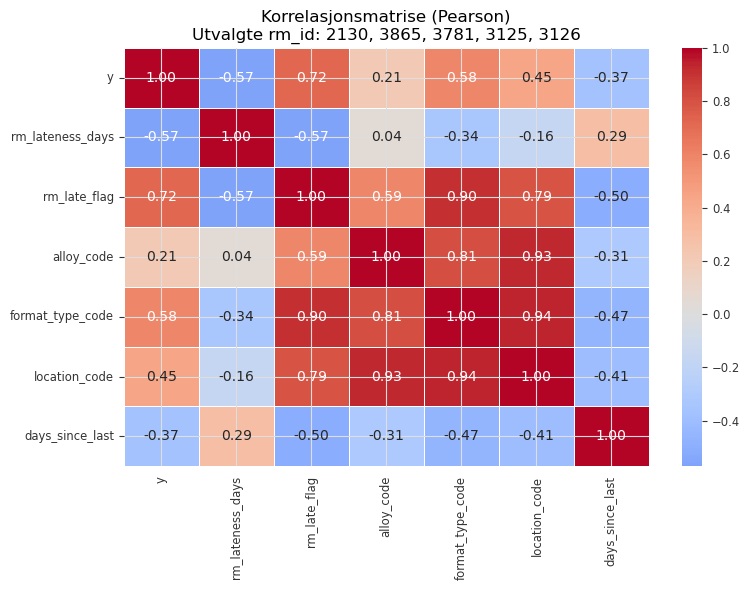

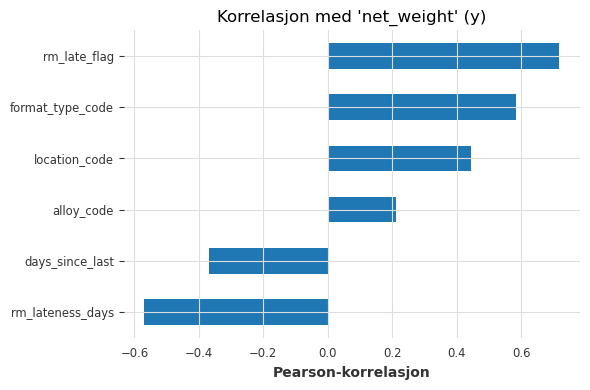

In [33]:
selected_rm_ids = [2130, 3865, 3781, 3125, 3126]

if "feature_df" not in globals():
    raise RuntimeError("feature_df finnes ikke - last datasettet først.")

subset = feature_df[feature_df["rm_id"].isin(selected_rm_ids)].copy()
subset = subset[subset["date"].dt.year == 2024]

num = subset.select_dtypes(include=[np.number]).copy()

for col in ["rm_id", "rm_id_enc"]:
    if col in num.columns:
        num.drop(columns=[col], inplace=True)

if "y" not in num.columns:
    raise RuntimeError("Fant ikke kolonnen 'y' (net_weight) i feature_df.")

corr = num.corr(method="pearson")

corr_y = corr["y"].sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Korrelasjonsmatrise (Pearson)\nUtvalgte rm_id: " + ", ".join(map(str, selected_rm_ids)))
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
corr_y.drop("y", errors="ignore").sort_values(ascending=True).plot.barh(color="tab:blue")
plt.title("Korrelasjon med 'net_weight' (y)")
plt.xlabel("Pearson-korrelasjon")
plt.tight_layout()
plt.show()

### 2.4.1) Exploring individual features

The correlation plots show how the engineered features relate to the target variable `net_weight`.  
`rm_late_flag`, `format_type_code`, and `location_code` have the strongest positive correlation with delivery weight, meaning that both the material format and location are important indicators of how large a shipment is.  

Features such as `rm_lateness_days` and `days_since_last` have negative correlations, which makes sense since longer gaps or delays between deliveries are often linked to smaller or less frequent shipments.  
The correlation matrix also shows that some of these categorical features are strongly related to each other, indicating a degree of multicollinearity.  
Overall, these results confirm that the engineered features capture meaningful patterns connected to shipment size and timing.


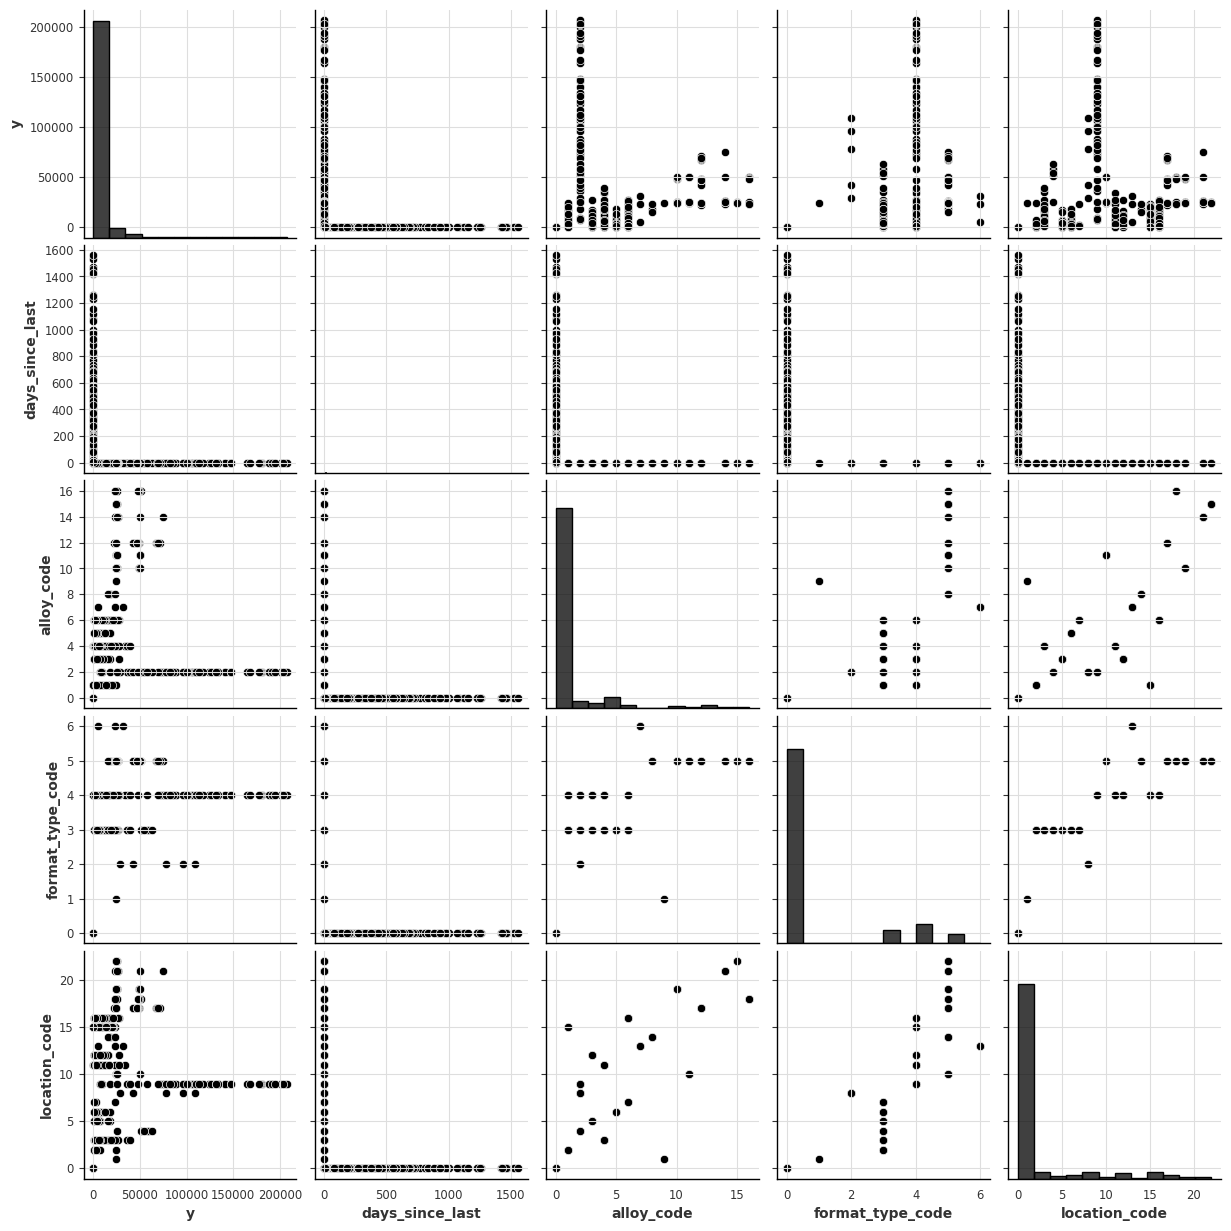

In [34]:
sns.pairplot(feature_df[["y","days_since_last","alloy_code","format_type_code","location_code"]].sample(2000))

### 2.4.2) Exploring Pairs and Groups of Features

Pair plots and correlation analysis were used to explore relationships between variables.  
The analysis showed that:  
- `alloy_code`, `format_type_code`, and `location_code` are categorical with some overlap.  
- There are weak linear relationships, but possible interaction effects between certain features.  

This exploration helped identify correlations, redundancy, and potential interaction effects prior to model training.


In [35]:
# --- Build series
past_covariate_cols = ["days_since_last","rm_lateness_days","rm_late_flag","alloy_code","format_type_code","location_code"]
target_series, past_covs_train, past_covs_full, ts_y_full_map = {}, {}, {}, {}

for rm, grp in feature_df.groupby("rm_id"):
    grp = grp.sort_values("date")
    past_cov_df = grp[["date"] + past_covariate_cols]
    ts_y_full = TimeSeries.from_dataframe(grp, time_col="date", value_cols="y", freq="D")
    ts_past_full = TimeSeries.from_dataframe(past_cov_df, time_col="date", value_cols=past_covariate_cols, freq="D")
    rm_code = int(grp["rm_id_enc"].iloc[0])
    static_covs = pd.DataFrame({"rm_id_enc":[rm_code]})
    ts_y_full = ts_y_full.with_static_covariates(static_covs)
    ts_past_full = ts_past_full.with_static_covariates(static_covs)
    ts_y_train = ts_y_full.drop_after(TRAIN_END)
    ts_past_tr = ts_past_full.drop_after(TRAIN_END)
    target_series[int(rm)] = ts_y_train
    past_covs_train[int(rm)] = ts_past_tr
    past_covs_full[int(rm)] = ts_past_full
    ts_y_full_map[int(rm)] = ts_y_full

### 2.4.3) Feature Selection

We selected most relevant features for modeling, ensuring consistent formats and no missing values.  
Categorical variables were encoded, and all predictors were standardized for use in the time series model.  
The final features used were `days_since_last`, `rm_lateness_days`, `rm_late_flag`, `alloy_code`, `format_type_code`, and `location_code`.  

The model itself creates **lags** over 151 days to capture temporal dependencies.  
We also experimented with additional features such as weekend indicators, holiday flags, rolling sums, and rolling means,  
but these reduced performance and stability, so they were excluded from the final setup.  
The final selection provided a good balance between simplicity, interpretability, and predictive accuracy.


### 2.5) Feature Engineering Summary

We first aggregated the deliveries to daily totals, filling missing days with zeros to make the time series continuous.  
Then we added several new features that capture important temporal and operational patterns:

- **`days_since_last`** – number of days since the previous delivery.  
  Helps the model understand regularity and gaps between shipments.
- **`rm_lateness_days`** and **`rm_late_flag`** – measure how late or on-time a delivery was based on purchase order data.  
  These features describe delays that often affect future deliveries.
- **`alloy_code`**, **`format_type_code`**, **`location_code`** – encoded material properties and logistics information.  
  They let the model learn that different materials and delivery points behave differently.
- **`rm_id_enc`** – a categorical static covariate identifying each material.  
  This ensures that the model keeps separate patterns for each `rm_id` while still training jointly.

Together, these engineered features provide the models with both short-term dynamics (lags and delivery gaps) and static context (material characteristics).  
This combination was essential for achieving stable and realistic forecasts across many different materials.


# 3) Models

### 3.1) Hyperparameter reasoning

To avoid overfitting we limited how deep the trees are and used relatively strong regularization.
During testing we noticed that our Kaggle score improved when the model was slightly underfitted
rather than overfitted, because overfitting caused large overpredictions which are heavily punished by the asymmetric loss.

The number of `lags` was important since it controls how much historical information the model can use.
Using too few lags made the model miss long-term patterns, while too many lags increased training time
and noise. We found around 151 lags to give a good balance between context and stability.

The parameter `categorical_static_covariates=["rm_id_enc"]` was also important.
This tells the model that each time series belongs to a specific `rm_id`.
By encoding `rm_id` as a categorical feature, the model learns id-specific behaviour,
for example that some id's are delivered more often or in different quantities.
Without this information the model tended to mix patterns between id's and became less accurate.


We initially attempted to use grid search for hyperparameter tuning, but the resulting parameter sets performed significantly worse than our manually chosen configuration.  
Because of this, we decided to manually specify the parameters instead.  
Through targeted experiments and leaderboard validation, we found that adjusting depth, learning rate, and regularization by hand led to much better generalization and overall performance.



### 3.2) Model selection reasoning

We mainly used **LightGBM** and **XGBoost** because both are gradient boosting models that handle tabular time-series data efficiently and perform well with limited data per series.
They are fast to train, easy to tune, and support quantile regression, which was required for this task since the evaluation metric is an asymmetric quantile loss.

We also tested **AutoGluon**, but it tended to overpredict heavily on our data.

Because of that, we decided to use manual gradient-boosting setups instead, where we had better control over regularization and model complexity.
Overall, LightGBM gave the most stable results and slightly better Kaggle performance, while XGBoost was used mainly to confirm that our results were not model-specific.

## LightGBM

In [ ]:
# --- Train model
BASE_LGBM = dict(
    num_leaves=100, 
    max_depth=8,   
    reg_lambda=25, 
    reg_alpha=20,
)

def make_model() -> LightGBMModel:
    return LightGBMModel(
        lags=151,
        lags_past_covariates=151,
        categorical_static_covariates=["rm_id_enc"], 
        output_chunk_length=151,
        random_state=42,
        verbose=-1,
        **BASE_LGBM,
    )

ts_train_list   = [target_series[k]   for k in sorted(target_series.keys())]
past_train_list = [past_covs_train[k] for k in sorted(target_series.keys())]

modelA = make_model()
modelA.fit(series=ts_train_list, past_covariates=past_train_list)

LightGBMModel(lags=151, lags_past_covariates=151, lags_future_covariates=None, output_chunk_length=151, output_chunk_shift=0, add_encoders=None, likelihood=None, quantiles=None, random_state=42, multi_models=True, use_static_covariates=True, categorical_past_covariates=None, categorical_future_covariates=None, categorical_static_covariates=['rm_id_enc'], verbose=-1, num_leaves=100, max_depth=8, reg_lambda=30, reg_alpha=20)

### Prediction

In [37]:
#--- Generate forecasts ---
horizon_days = (FORECAST_END - FORECAST_START).days + 1
per_rm_predictions = []

for rm, ts_y in target_series.items():
    past_full_ts = past_covs_full[rm]

    
    pred_ts = modelA.predict(n=horizon_days, series=ts_y, past_covariates=past_full_ts)
    preds = pred_ts.values().flatten().astype(float)

    forecast_index = pd.date_range(FORECAST_START, FORECAST_END, freq="D")
    rm_frame = pd.DataFrame({"rm_id": int(rm), "date": forecast_index, "y_pred_model": preds})

    
    y_pred = np.maximum(rm_frame["y_pred_model"].to_numpy().astype(float), 0.0)

    
    df_2024 = feature_df[
        (feature_df["rm_id"] == rm) &
        (feature_df["date"] >= pd.Timestamp("2024-01-01")) &
        (feature_df["date"] <= pd.Timestamp("2024-12-31"))
    ]
    cap_2024 = (1.1 * float(df_2024["y"].max())) if (not df_2024.empty and df_2024["y"].notna().any()) else np.inf
    y_pred = np.minimum(y_pred, cap_2024)

    
    jan_mask = (forecast_index.month == 1) & (forecast_index.day.isin([1, 2]))
    y_pred[jan_mask] = 0.0

    rm_frame["y_pred"] = y_pred
    per_rm_predictions.append(rm_frame[["rm_id", "date", "y_pred"]])

if not per_rm_predictions:
    raise RuntimeError("Ingen prediksjoner generert.")

pred_daily = pd.concat(per_rm_predictions, ignore_index=True).sort_values(["rm_id", "date"])

pred_daily.to_csv("predictions_daily.csv", index=False)
pred_lgbm = pred_daily.copy()


## XGBoost

In [ ]:
#--- Train XGB model
BASE_XGB = dict(
    max_depth=8,
    reg_alpha=20,
    reg_lambda=25,
    random_state=42,
    num_leaves=100,
    verbosity=0,        
)

def make_model() -> XGBModel:
    return XGBModel(
        lags=151,
        lags_past_covariates=151,
        categorical_static_covariates=["rm_id_enc"],  
        output_chunk_length=151,
        **BASE_XGB,
    )


ts_train_list   = [target_series[k]   for k in sorted(target_series.keys())]
past_train_list = [past_covs_train[k] for k in sorted(target_series.keys())]


modelB = make_model()
modelB.fit(series=ts_train_list, past_covariates=past_train_list)

XGBModel(lags=151, lags_past_covariates=151, lags_future_covariates=None, output_chunk_length=151, output_chunk_shift=0, add_encoders=None, likelihood=None, quantiles=None, random_state=42, multi_models=True, use_static_covariates=True, categorical_static_covariates=['rm_id_enc'], max_depth=8, reg_alpha=20, reg_lambda=30, num_leaves=100, verbosity=0)

### Prediction

In [39]:
#--- Generate forecasts ---
horizon_days = (FORECAST_END - FORECAST_START).days + 1
per_rm_predictions = []

for rm, ts_y in target_series.items():
    past_full_ts = past_covs_full[rm]

    ts_y = ts_y.astype(np.float32)
    past_full_ts = past_full_ts.astype(np.float32)

    pred_ts = modelB.predict(
        n=horizon_days,
        series=ts_y,
        past_covariates=past_full_ts
    )
    preds = pred_ts.values().flatten().astype(float)

    forecast_index = pd.date_range(FORECAST_START, FORECAST_END, freq="D")
    rm_frame = pd.DataFrame({"rm_id": int(rm), "date": forecast_index, "y_pred_model": preds})

    y_pred = np.maximum(rm_frame["y_pred_model"].to_numpy(dtype=float), 0.0)

    df_2024 = feature_df[
        (feature_df["rm_id"] == rm) &
        (feature_df["date"] >= pd.Timestamp("2024-01-01")) &
        (feature_df["date"] <= pd.Timestamp("2024-12-31"))
    ]
    cap_2024 = (1.1 * float(df_2024["y"].max())) if (not df_2024.empty and df_2024["y"].notna().any()) else np.inf
    y_pred = np.minimum(y_pred, cap_2024)

    jan_mask = (forecast_index.month == 1) & (np.isin(forecast_index.day, [1, 2]))
    y_pred[jan_mask] = 0.0

    rm_frame["y_pred"] = y_pred
    per_rm_predictions.append(rm_frame[["rm_id", "date", "y_pred"]])

if not per_rm_predictions:
    raise RuntimeError("Ingen prediksjoner generert.")

pred_daily = (
    pd.concat(per_rm_predictions, ignore_index=True)
      .sort_values(["rm_id", "date"])
)

# Save
pred_daily.to_csv("predictions_daily.csv", index=False)
pred_xgb = pred_daily.copy()

In [40]:
#--- Map prediction and make submission ---
DATA_DIR = Path('./data')
PREDICTION_MAPPING_PATH = DATA_DIR / 'prediction_mapping.csv'
SAMPLE_SUB_PATH = DATA_DIR / 'sample_submission.csv'

pred_map = pd.read_csv(PREDICTION_MAPPING_PATH)
sample_sub = pd.read_csv(SAMPLE_SUB_PATH)

# Parse dates
pred_daily["date"] = pd.to_datetime(pred_daily["date"])
pred_map["forecast_end_date"] = pd.to_datetime(pred_map["forecast_end_date"])

# Align rm_id types
pred_daily["rm_id"] = pred_daily["rm_id"].round().astype("Int64")
pred_map["rm_id"] = pred_map["rm_id"].round().astype("Int64")

# Collapse duplicates and compute cumsum
daily_summed = (
    pred_daily.groupby(["rm_id", "date"], as_index=False)["y_pred"]
    .sum()
    .sort_values(["rm_id", "date"])
)
daily_summed["cum_pred"] = daily_summed.groupby("rm_id")["y_pred"].cumsum()
# Deduplicate pred_map by ID
pred_map_unique = pred_map.sort_values(["ID"]).drop_duplicates(subset=["ID"], keep="first")

# Compute cum value for each ID per rm_id by manual asof within each group
results = []
for rm, grp_end in pred_map_unique.groupby("rm_id"):
    # End dates for this rm_id
    end_df = grp_end[["ID", "forecast_end_date"]].sort_values("forecast_end_date").reset_index(drop=True)
    # History for this rm_id
    hist = daily_summed[daily_summed["rm_id"] == rm][["date", "cum_pred"]].sort_values("date").reset_index(drop=True)
    if hist.empty:
        # No history -> zeros
        tmp = end_df.copy()
        tmp["predicted_weight"] = 0.0
    else:
        # Use merge_asof without 'by'
        tmp = pd.merge_asof(
            end_df, hist,
            left_on="forecast_end_date",
            right_on="date",
            direction="backward",
            allow_exact_matches=True
        ).drop(columns=["date"])
        tmp = tmp.rename(columns={"cum_pred": "predicted_weight"})
        tmp["predicted_weight"] = tmp["predicted_weight"].fillna(0.0)
    results.append(tmp[["ID", "predicted_weight"]])

merged_all = pd.concat(results, ignore_index=True)

# Align to sample_submission
submission = sample_sub[["ID"]].merge(merged_all, on="ID", how="left")
submission["predicted_weight"] = submission["predicted_weight"].fillna(0.0)

# Ensure unique IDs
assert not submission["ID"].duplicated().any(), "Duplicate ID values found in submission"

# Save
out_path = "./data/submission_mat_38.csv"
submission.to_csv(out_path, index=False)

{"status": "ok", "rows": len(submission), "path": out_path}

{'status': 'ok', 'rows': 30450, 'path': './data/submission_mat_38.csv'}

# 4) Feature Imporantce

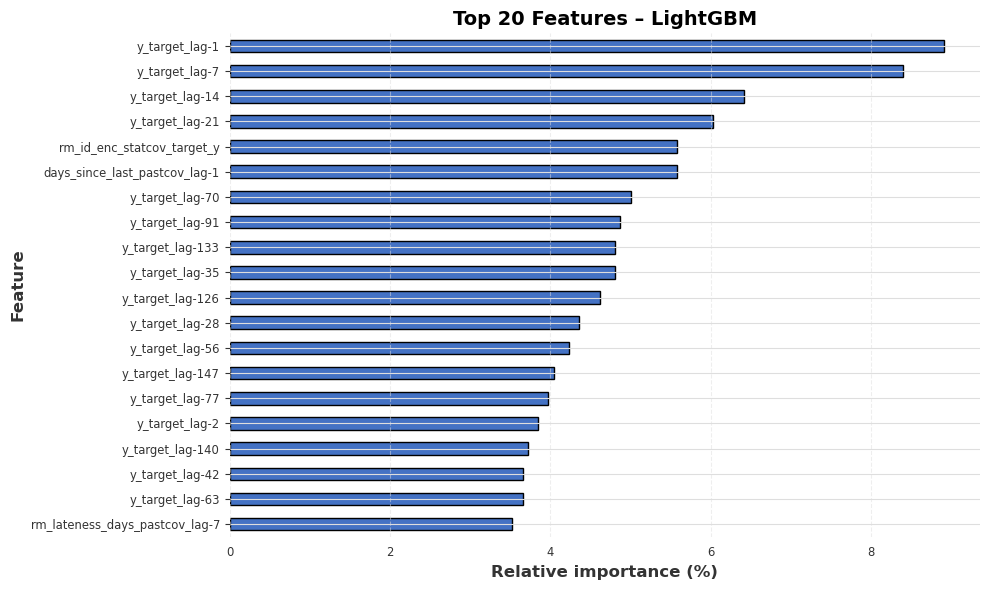

Model supports multi-output; a single estimator forecasts all the horizons and components.


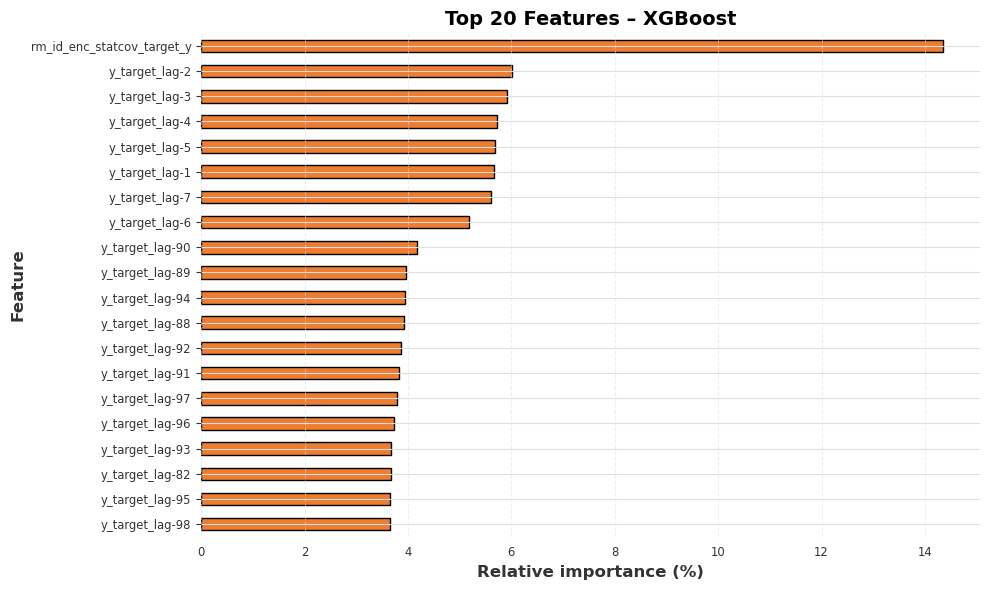

In [41]:
def plot_feature_importances(model, model_name, top_k=20, color="#4C72B0"):
    """Plots the top-k feature importances for a trained LightGBM/XGBoost model."""
    # Extract importances
    est = model.get_estimator(horizon=0, target_dim=0)
    importances = est.feature_importances_
    feature_names = model.lagged_feature_names

    
    fi = pd.Series(importances, index=feature_names)
    fi = fi.sort_values(ascending=False)
    fi_top = fi.head(top_k)
    fi_top = 100 * fi_top / fi_top.sum()  

    
    plt.figure(figsize=(10, 6))
    fi_top.iloc[::-1].plot(kind="barh", color=color, edgecolor="black")

    plt.title(f"Top {top_k} Features – {model_name}", fontsize=14, weight="bold")
    plt.xlabel("Relative importance (%)", fontsize=12)
    plt.ylabel("Feature", fontsize=12)
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


plot_feature_importances(modelA, "LightGBM", top_k=20, color="#4472C4")


plot_feature_importances(modelB, "XGBoost", top_k=20, color="#ED7D31")


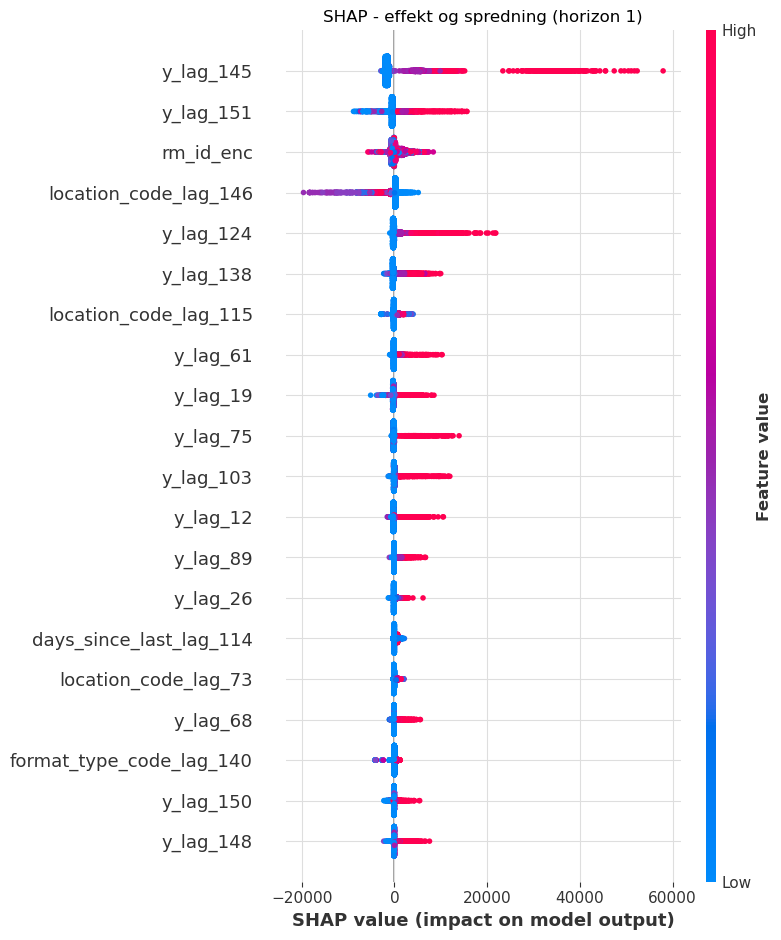

In [42]:
n_y_lags = 151
n_past_lags = 151
static_names = ["rm_id_enc"]
max_rows_per_series = 600  # begrens rader per serie for hastighet

def _get_col_indices(components, wanted_cols):
    """Returnerer posisjoner for wanted_cols i components, robust for både Index og list."""
    idxs = []
    for c in wanted_cols:
        try:
            # pandas Index:
            idxs.append(components.get_loc(c))
        except AttributeError:
            # list/tuple:
            idxs.append(components.index(c))
    return idxs

def build_lag_matrix(series_list, past_list, global_cutoff_time):
    X_rows, y_rows = [], []

    for s, p in zip(series_list, past_list):
        # clamp cutoff per serie
        cutoff_i = min(global_cutoff_time, s.end_time(), p.end_time())
        try:
            s_i = s.drop_after(cutoff_i)
            p_i = p.drop_after(cutoff_i)
        except Exception:
            continue

        s_sync = s_i.slice_intersect(p_i)
        p_sync = p_i.slice_intersect(s_i)

        T = len(s_sync)
        if T < n_y_lags + 2:
            continue

        s_mat = s_sync.values(copy=False)            
        s_vals = s_mat.reshape(-1).astype(float)     

        p_mat_all = p_sync.values(copy=False)        
        keep_cols = [c for c in past_covariate_cols if c in list(p_sync.components)]
        if len(keep_cols) > 0:
            idxs = _get_col_indices(p_sync.components, keep_cols)
            p_mat = p_mat_all[:, idxs].astype(float) 
        else:
            p_mat = np.empty((T, 0), dtype=float)

        static_vec = None
        if s_sync.static_covariates is not None and "rm_id_enc" in s_sync.static_covariates.columns:
            static_vec = float(s_sync.static_covariates["rm_id_enc"].iloc[0])

        start_t = n_y_lags
        end_t   = T - 1
        if end_t - start_t < 1:
            continue

        ts_list = list(range(start_t, end_t))
        if len(ts_list) > max_rows_per_series:
            ts_list = ts_list[-max_rows_per_series:]

        for t in ts_list:
            ylags = s_vals[t - np.arange(1, n_y_lags + 1)]
            if p_mat.shape[1] > 0:
                plags = []
                for j in range(p_mat.shape[1]):
                    col = p_mat[:, j]
                    plags.append(col[t - np.arange(1, n_past_lags + 1)])
                plags = np.concatenate(plags, axis=0)
            else:
                plags = np.empty((0,), dtype=float)

            if static_vec is not None:
                x = np.concatenate([ylags, plags, np.array([static_vec], dtype=float)])
            else:
                x = np.concatenate([ylags, plags])

            X_rows.append(x)
            y_rows.append(s_vals[t])

    if not X_rows:
        raise RuntimeError("Fikk ingen rader til SHAP/PDP: for lite historikk etter clamping av cutoff.")

    X = np.vstack(X_rows)
    y = np.asarray(y_rows)

    colnames = [f"y_lag_{i}" for i in range(1, n_y_lags + 1)]
    for col in past_covariate_cols:
        colnames += [f"{col}_lag_{i}" for i in range(1, n_past_lags + 1)]
    if "rm_id_enc" in static_names:
        colnames += ["rm_id_enc"]

    return pd.DataFrame(X, columns=colnames), pd.Series(y, name="y")

rm_ids_sorted  = sorted(target_series.keys())
series_list_tr = [target_series[k] for k in rm_ids_sorted]
past_list_full = [past_covs_full[k] for k in rm_ids_sorted]

X_tab, y_tab = build_lag_matrix(series_list_tr, past_list_full, TRAIN_END)

est0 = modelA.model.estimators_[0]

sample_n = min(5000, len(X_tab))
X_sample = X_tab.sample(sample_n, random_state=42)

explainer = shap.TreeExplainer(est0)
shap_values = explainer(X_sample)


shap.summary_plot(shap_values, X_sample, show=False)
plt.title("SHAP - effekt og spredning (horizon 1)")
plt.tight_layout(); plt.show()


### 4.1) Feature importance summary

Both models identify time-based features as the most influential for forecasting.  
For **LightGBM**, the most important predictors are recent lags of the target (`y_target_lag-1`, `y_target_lag-7`, `y_target_lag-14`), along with `days_since_last_pastcov_lag-1`, showing that short-term delivery history and time gaps strongly influence future shipments.  
For **XGBoost**, the feature `rm_id_enc_statcov_target_y` dominates, meaning the model relies heavily on the material-specific static covariate to distinguish between different raw materials.  
The remaining top features are also recent target lags, confirming that both models primarily learn from short-term temporal dependencies rather than static material attributes.

Overall, the comparison shows that **LightGBM distributes importance more evenly** across multiple recent lags and time-based covariates, while **XGBoost places more weight on the material identity**.  
This suggests that LightGBM captures smoother temporal patterns, whereas XGBoost relies more on per-material behavior.


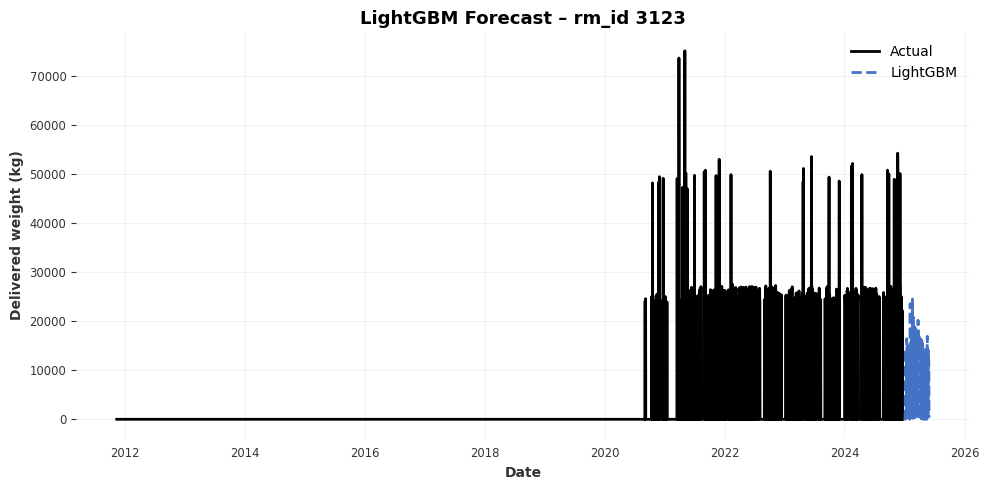

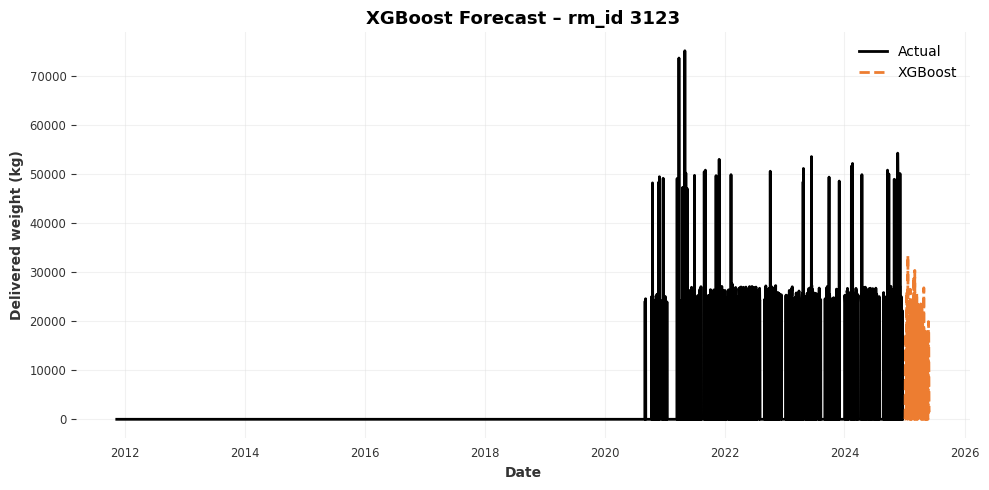

In [43]:
example_rm = 3123  

# --- Actual vs LightGBM ---
actual_df = feature_df[feature_df["rm_id"] == example_rm][["date", "y"]]
pred_df   = pred_lgbm[pred_lgbm["rm_id"] == example_rm][["date", "y_pred"]]

merged = actual_df.merge(pred_df, on="date", how="outer").sort_values("date").set_index("date")

plt.figure(figsize=(10, 5))
plt.plot(merged.index, merged["y"], label="Actual", color="black", linewidth=2)
plt.plot(merged.index, merged["y_pred"], "--", label="LightGBM", linewidth=2, color="#4472C4")

plt.title(f"LightGBM Forecast – rm_id {example_rm}", fontsize=13, weight="bold")
plt.ylabel("Delivered weight (kg)")
plt.xlabel("Date")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


# --- Actual vs XGBoost ---
actual_df = feature_df[feature_df["rm_id"] == example_rm][["date", "y"]]
pred_df   = pred_xgb[pred_xgb["rm_id"] == example_rm][["date", "y_pred"]]

merged = actual_df.merge(pred_df, on="date", how="outer").sort_values("date").set_index("date")

plt.figure(figsize=(10, 5))
plt.plot(merged.index, merged["y"], label="Actual", color="black", linewidth=2)
plt.plot(merged.index, merged["y_pred"], "--", label="XGBoost", linewidth=2, color="#ED7D31")

plt.title(f"XGBoost Forecast – rm_id {example_rm}", fontsize=13, weight="bold")
plt.ylabel("Delivered weight (kg)")
plt.xlabel("Date")
plt.grid(alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

### Model Evaluation
We evaluated performance based on the Kaggle leaderboard score, which uses the asymmetric quantile loss at α = 0.2.  
This metric penalizes overprediction more heavily than underprediction.  
Both models achieved stable public leaderboard scores, confirming that the underpredicting behavior was consistent and aligned with the competition goal.



## 5) Discussion and Conclusion

Both LightGBM and XGBoost were able to produce stable and realistic forecasts for the raw material deliveries.  
LightGBM gave smoother and more conservative results, while XGBoost responded faster to short-term changes and showed more variance.  
The most important features were lag values, `days_since_last`, and `rm_lateness_days`, which helped the models capture delivery frequency and timing patterns.  
Including static information such as `rm_id_enc` also improved material-specific predictions.

The models both tended to underpredict, which was desirable given the asymmetric quantile loss with α = 0.2.  
This conservative bias reduced the risk of overestimation and aligns with the practical goal of the task.  
Overall, the results show that a combination of feature-based time series modeling and gradient-boosted trees gives a good balance between general trends and individual material behavior.  
The approach achieved the goal of making cautious but informative forecasts that generalize well across materials.
